Baseline SNR Matrix
----------------------------------------------------------------------
[[1.47209525 1.99071064 1.03602485 1.40634513 1.04045493]
 [1.00679373 1.24114376 1.1453754  1.29648329 1.98738394]]

Expected reward of each arm
----------------------------------------------------------------------
Arm (0, 1): 5.290106
Arm (0, 2): 5.209873
Arm (0, 3): 5.333480
Arm (0, 4): 5.753947
Arm (1, 0): 5.376030
Arm (1, 2): 5.506307
Arm (1, 3): 5.629913
Arm (1, 4): 6.050380
Arm (2, 0): 4.729139
Arm (2, 1): 4.939648
Arm (2, 3): 4.983021
Arm (2, 4): 5.403489
Arm (3, 0): 5.034487
Arm (3, 1): 5.244996
Arm (3, 2): 5.164763
Arm (3, 4): 5.708836
Arm (4, 0): 4.733467
Arm (4, 1): 4.943976
Arm (4, 2): 4.863743
Arm (4, 3): 4.987349

Optimal Arm
----------------------------------------------------------------------
  Channel Pair   : (1, 4)
  Expected Rate  : 6.050380

Delta_i (suboptimality gaps)
----------------------------------------------------------------------
Arm (0, 1): Δ_i = 0.760274
Arm (0

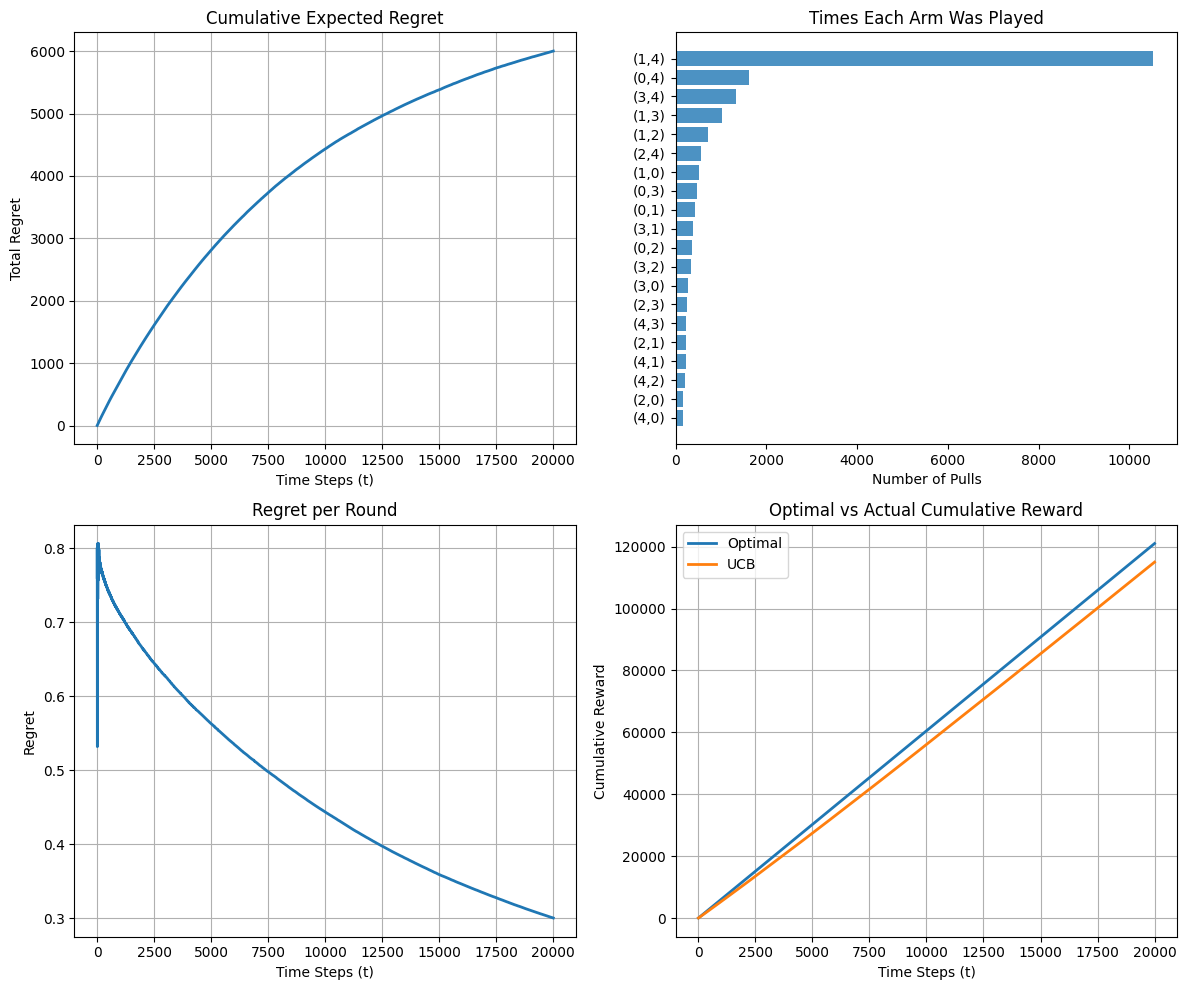

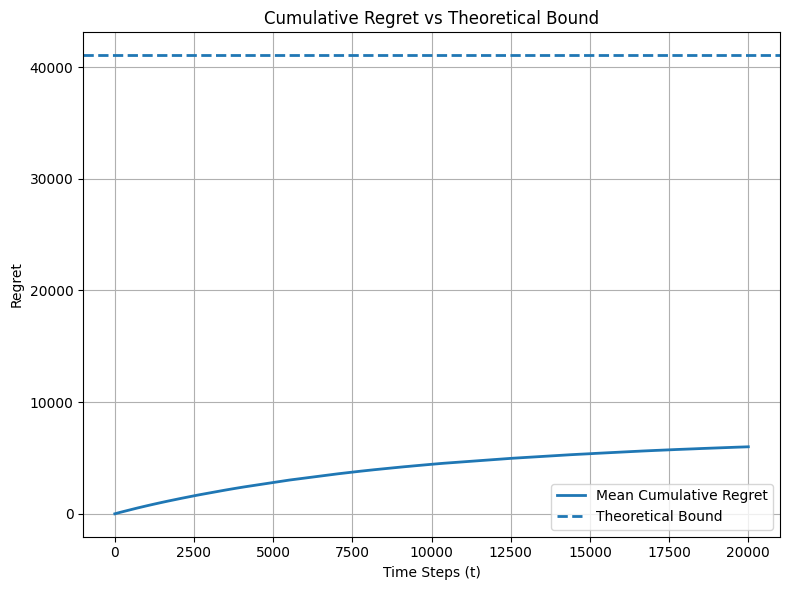

In [1]:
# Case A (Plots and prints)
import numpy as np
import matplotlib.pyplot as plt

K = 5
epsilon = 0.6
T = 20000
epochs = 10

# Create arms
arms = []
for j1 in range(K):
    for j2 in range(K):
        if j1 != j2:
            arms.append((j1, j2))

n_arms = len(arms)

# Create sample baseline SNR parameters
rng_base = np.random.default_rng(63)
snr_base = rng_base.uniform(0.8, 2.0, (2, 5))

print("Baseline SNR Matrix")
print("-"*70)
print(snr_base)

# Expected reward computation
def F(s):
    return (1 + 10*s)*(np.log(1 + 10*s) - 1) / 10

def expected_reward(snr_base, epsilon):
    mu_arms = []

    for j1 in range(K):
        for j2 in range(K):
            if j1 != j2:
                base1 = snr_base[0, j1]
                base2 = snr_base[1, j2]

                mu1 = (F(base1 + epsilon) - F(base1 - epsilon)) / (2 * epsilon)
                mu2 = (F(base2 + epsilon) - F(base2 - epsilon)) / (2 * epsilon)

                mu_arms.append(mu1 + mu2)

    return mu_arms

mu_arms = expected_reward(snr_base, epsilon)

# Best arm
best_idx = np.argmax(mu_arms)
best_mu = mu_arms[best_idx]
best_arm = arms[best_idx]

#  REWARD RANGE R
snr_min = 0.8 - epsilon
snr_max = 2.0 + epsilon
r_min = 2.0 * np.log(1.0 + 10.0 * snr_min)
r_max = 2.0 * np.log(1.0 + 10.0 * snr_max)
R = r_max - r_min

# Arrays to store results over epochs
all_cumulative_regret = np.zeros((epochs,T))
all_regret_per_round = np.zeros((epochs,T))
all_cumulative_actual_reward = np.zeros((epochs,T))
all_arm_pulls = np.zeros((epochs, n_arms))

time_axis = np.arange(1, T + 1)

# UCB simulation
for epoch in range(epochs):
    # Reset for this epoch
    delta = np.zeros(T)
    N = np.zeros(n_arms)
    sum_rewards = np.zeros(n_arms)
    actual_rewards = np.zeros(T)

    rng = np.random.default_rng(epoch)

    for t in range(1, T + 1):
      # Select arm
      if t <= n_arms:
        chosen_arm = t - 1
      else:
        exploit_term = sum_rewards / N
        explore_term = R * np.sqrt((2*np.log(T))/ N)
        ucb_score = exploit_term + explore_term
        chosen_arm = np.argmax(ucb_score)

      # Pull the arm
      j1, j2 = arms[chosen_arm]
      base1 = snr_base[0, j1]
      base2 = snr_base[1, j2]

      # Generate instantaneous noise for THIS round only
      snr_inst1 = rng.uniform(base1 - epsilon, base1 + epsilon)
      snr_inst2 = rng.uniform(base2 - epsilon, base2 + epsilon)

      # Compute rate value
      rate1 = np.log(1 + 10*snr_inst1)
      rate2 = np.log(1 + 10*snr_inst2)

      # Compute sum-rate
      total_rate = rate1 + rate2
      actual_rewards[t-1] = total_rate

      # Update terms
      N[chosen_arm] += 1
      sum_rewards[chosen_arm] += total_rate

      # Store delta
      delta[t-1] = best_mu - mu_arms[chosen_arm]

    # REGRET CALCULATIONS
    cumulative_regret = np.cumsum(delta)
    regret_per_round = cumulative_regret / time_axis

    # REWARD CALCULATIONS
    cumulative_actual_reward = np.cumsum(actual_rewards)

    # Store this epoch's results
    all_cumulative_regret[epoch] = cumulative_regret
    all_regret_per_round[epoch] = regret_per_round
    all_cumulative_actual_reward[epoch] = cumulative_actual_reward
    all_arm_pulls[epoch] = N

# Average over epochs
mean_cumulative_regret = np.mean(all_cumulative_regret, axis=0)
mean_regret_per_round = np.mean(all_regret_per_round, axis=0)
mean_cumulative_actual_reward = np.mean(all_cumulative_actual_reward, axis=0)
mean_arm_pulls = np.mean(all_arm_pulls, axis=0)

optimal_cumulative_reward = best_mu * time_axis

# RESULTS SUMMARY
print("\nExpected reward of each arm")
print("-"*70)
for i in range(n_arms):
    print(f"Arm {arms[i]}: {mu_arms[i]:.6f}")

print("\nOptimal Arm")
print("-"*70)
print(f"  Channel Pair   : {best_arm}")
print(f"  Expected Rate  : {best_mu:.6f}")

delta_i = [best_mu - mu for mu in mu_arms]
print("\nDelta_i (suboptimality gaps)")
print("-"*70)

for i in range(n_arms):
    print(f"Arm {arms[i]}: Δ_i = {delta_i[i]:.6f}")

most_played_idx = np.argmax(mean_arm_pulls)
most_played_arm = arms[most_played_idx]

print("\nMost Played Arm")
print("-"*70)
print(f"  Channel Pair   : {most_played_arm}")
print(f"  Times Played   : {int(mean_arm_pulls[most_played_idx])}")

print("\nPerformance")
print("-"*70)
print(f"  Total Regret            : {mean_cumulative_regret[-1]:.6f}")
print(f"  Average Regret per Round: {mean_regret_per_round[-1]:.6f}")
print(f"  Time Horizon (T)        : {T}")

print("\nArm Pull Statistics")
print("-"*70)
print(f"{'Arm (j1,j2)':>15} | {'Pulls':>10}")
print("-"*70)

for a in range(n_arms):
    print(f"{str(arms[a]):>15} | {int(mean_arm_pulls[a]):>10}")
print()

# Suboptimality gaps excluding the optimal arm
delta_sub = np.array([best_mu - mu_arms[i] for i in range(n_arms) if i != best_idx])

# Theoretical bound at the final horizon T
bound = np.sum((8 * R**2 * np.log(T)) / delta_sub) + n_arms * R * T**(-2)

print(f"Theoretical Bound")
print("-"*70)
print(f"  T = {T} : {bound}\n")
# PLOTTING
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Cumulative Regret
axes[0,0].plot(mean_cumulative_regret, color='tab:blue', linewidth=2)
axes[0,0].set_title("Cumulative Expected Regret")
axes[0,0].set_xlabel("Time Steps (t)")
axes[0,0].set_ylabel("Total Regret")
axes[0,0].grid(True)

# 2. Number of pulls per arm (Sorted)
sorted_idx = np.argsort(mean_arm_pulls)
arm_labels = [f"({arms[i][0]},{arms[i][1]})" for i in sorted_idx]
axes[0,1].barh(range(n_arms), mean_arm_pulls[sorted_idx], color='tab:blue', alpha=0.8)
axes[0,1].set_yticks(range(n_arms))
axes[0,1].set_yticklabels(arm_labels)
axes[0,1].set_title("Times Each Arm Was Played")
axes[0,1].set_xlabel("Number of Pulls")

# 3. Regret per Round (Average Regret)
axes[1,0].plot(time_axis, mean_regret_per_round, color='tab:blue', linewidth=2)
axes[1,0].set_title("Regret per Round")
axes[1,0].set_xlabel("Time Steps (t)")
axes[1,0].set_ylabel("Regret")
axes[1,0].grid(True)

# 4. Optimal vs Actual Cumulative Reward
axes[1,1].plot(time_axis, optimal_cumulative_reward, label="Optimal", linewidth=2)
axes[1,1].plot(time_axis, mean_cumulative_actual_reward, label="UCB", linewidth=2)
axes[1,1].set_title("Optimal vs Actual Cumulative Reward")
axes[1,1].set_xlabel("Time Steps (t)")
axes[1,1].set_ylabel("Cumulative Reward")
axes[1,1].legend()
axes[1,1].grid(True)

plt.tight_layout()
plt.show()

# 5. Cumulative Regret vs Theoretical Bound
print()
plt.figure(figsize=(8, 6))
plt.plot(time_axis, mean_cumulative_regret, linewidth=2, label='Mean Cumulative Regret')
plt.axhline(y=bound, linestyle='--', linewidth=2, label='Theoretical Bound')

plt.title("Cumulative Regret vs Theoretical Bound")
plt.xlabel("Time Steps (t)")
plt.ylabel("Regret")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Baseline SNR Matrix
----------------------------------------------------------------------
[[1.47209525 1.99071064 1.03602485 1.40634513 1.04045493]
 [1.00679373 1.24114376 1.1453754  1.29648329 1.98738394]]

Expected reward of each arm
----------------------------------------------------------------------
Arm (0, 1): 5.290106
Arm (0, 2): 5.209873
Arm (0, 3): 5.333480
Arm (0, 4): 5.753947
Arm (1, 0): 5.376030
Arm (1, 2): 5.506307
Arm (1, 3): 5.629913
Arm (1, 4): 6.050380
Arm (2, 0): 4.729139
Arm (2, 1): 4.939648
Arm (2, 3): 4.983021
Arm (2, 4): 5.403489
Arm (3, 0): 5.034487
Arm (3, 1): 5.244996
Arm (3, 2): 5.164763
Arm (3, 4): 5.708836
Arm (4, 0): 4.733467
Arm (4, 1): 4.943976
Arm (4, 2): 4.863743
Arm (4, 3): 4.987349

Optimal Arm
----------------------------------------------------------------------
  Channel Pair   : (1, 4)
  Expected Rate  : 6.050380

Suboptimality gaps
------------------------------------------------------------------------------------------
    Arm (j1,j2) |      

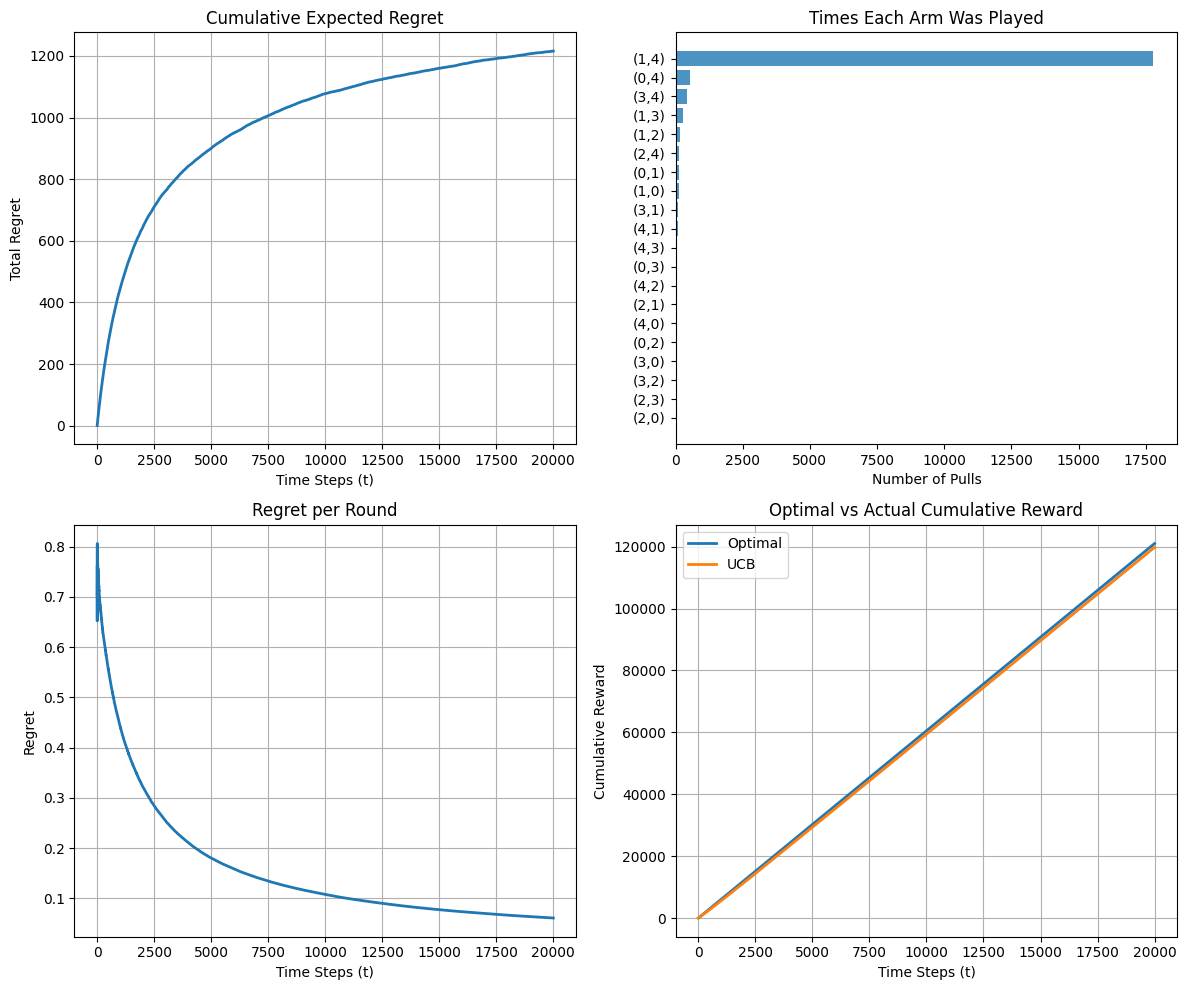

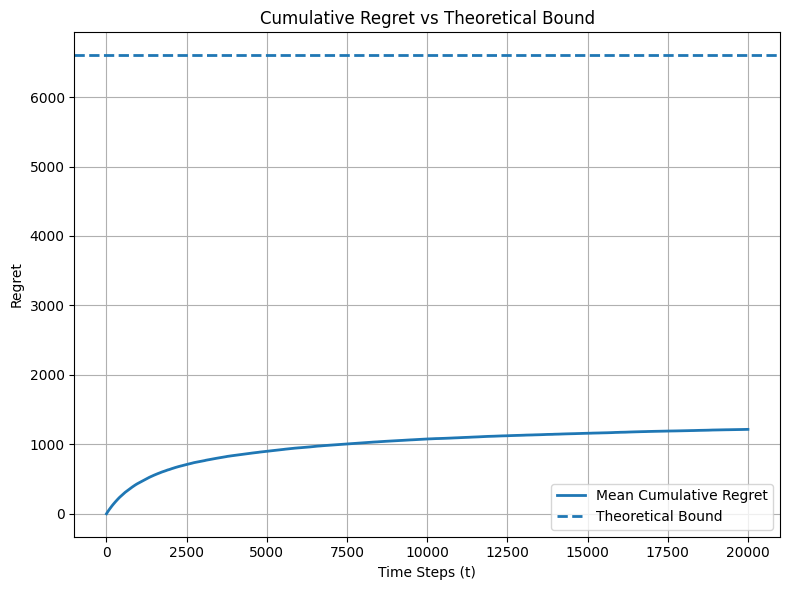

In [2]:
# Case B (Plots and prints)
import numpy as np
import matplotlib.pyplot as plt

K = 5
epsilon = 0.6
T = 20000
epochs = 10

# Create arms
arms = []
for j1 in range(K):
    for j2 in range(K):
        if j1 != j2:
            arms.append((j1, j2))

n_arms = len(arms)

# Create sample baseline SNR parameters
rng_base = np.random.default_rng(63)
snr_base = rng_base.uniform(0.8, 2.0, (2, 5))

print("Baseline SNR Matrix")
print("-"*70)
print(snr_base)

# Expected reward computation
def F(s):
    return (1 + 10*s)*(np.log(1 + 10*s) - 1) / 10

def expected_reward(snr_base, epsilon):
    # Store user-channel expectations
    mu1 = np.zeros(K)
    mu2 = np.zeros(K)

    # Compute expectations once per channel
    for j in range(K):
        base1 = snr_base[0, j]
        base2 = snr_base[1, j]

        mu1[j] = (F(base1 + epsilon) - F(base1 - epsilon)) / (2 * epsilon)
        mu2[j] = (F(base2 + epsilon) - F(base2 - epsilon)) / (2 * epsilon)

    # Compute joint arm rewards
    mu_arms = []
    for j1 in range(K):
        for j2 in range(K):
            if j1 != j2:
                mu_arms.append(mu1[j1] + mu2[j2])

    return mu1, mu2, mu_arms

mu1, mu2, mu_arms = expected_reward(snr_base, epsilon)

# Best arm
best_idx = np.argmax(mu_arms)
best_mu = mu_arms[best_idx]
best_arm = arms[best_idx]

#  REWARD RANGE R
snr_min = 0.8 - epsilon
snr_max = 2.0 + epsilon
r_min = np.log(1.0 + 10.0 * snr_min)
r_max = np.log(1.0 + 10.0 * snr_max)
R_UE = r_max - r_min

# Arrays to store results over epochs
all_cumulative_regret = np.zeros((epochs,T))
all_regret_per_round = np.zeros((epochs,T))
all_cumulative_actual_reward = np.zeros((epochs,T))
all_arm_pulls = np.zeros((epochs, n_arms))

time_axis = np.arange(1, T + 1)

# UCB simulation
for epoch in range(epochs):
    # Statistics for User 1
    N1 = np.zeros(K)
    sum_r1 = np.zeros(K)

    # Statistics for User 2
    N2 = np.zeros(K)
    sum_r2 = np.zeros(K)

    N_joint = np.zeros(n_arms)
    delta = np.zeros(T)
    actual_rewards = np.zeros(T)

    rng = np.random.default_rng(epoch)

    for t in range(1, T + 1):
      # Select arm
      if t <= K:
        j1 = t - 1
        j2 = t % K
      else:
        # Compute explore terms
        explore_term1 = R_UE*np.sqrt((2*np.log(T))/ N1)
        explore_term2 = R_UE*np.sqrt((2*np.log(T))/ N2)

        # Compute exploit terms
        exploit_term1 = sum_r1 / N1
        exploit_term2 = sum_r2 / N2

        # Compute total ucb terms
        ucb1 = exploit_term1 + explore_term1
        ucb2 = exploit_term2 + explore_term2

        # Find best non-conflicting pair (j1 != j2)
        best_score = -np.inf
        for p1 in range(K):
          for p2 in range(K):
            if p1 != p2:
              current_score = ucb1[p1] + ucb2[p2]
              if current_score > best_score:
                best_score = current_score
                j1, j2 = p1, p2

      chosen_arm = arms.index((j1, j2))

      # Generate instantaneous SNR for chosen channels
      snr_t1 = rng.uniform(snr_base[0, j1] - epsilon, snr_base[0, j1] + epsilon)
      snr_t2 = rng.uniform(snr_base[1, j2] - epsilon, snr_base[1, j2] + epsilon)

      # Compute individual rates
      r1 = np.log(1 + 10 * snr_t1)
      r2 = np.log(1 + 10 * snr_t2)

      # Compute total reward
      total_rate = r1 + r2
      actual_rewards[t - 1] = total_rate

      # Update Statistics
      N1[j1] += 1
      sum_r1[j1] += r1

      N2[j2] += 1
      sum_r2[j2] += r2
      N_joint[chosen_arm] += 1

      # Store delta
      delta[t-1] = best_mu - (mu1[j1] + mu2[j2])

    # REGRET CALCULATIONS
    cumulative_regret = np.cumsum(delta)
    regret_per_round = cumulative_regret / time_axis

    # REWARD CALCULATIONS
    cumulative_actual_reward = np.cumsum(actual_rewards)

    # Store this epoch's results
    all_cumulative_regret[epoch] = cumulative_regret
    all_regret_per_round[epoch] = regret_per_round
    all_cumulative_actual_reward[epoch] = cumulative_actual_reward
    all_arm_pulls[epoch] = N_joint

# Average over epochs
mean_cumulative_regret = np.mean(all_cumulative_regret, axis=0)
mean_regret_per_round = np.mean(all_regret_per_round, axis=0)
mean_cumulative_actual_reward = np.mean(all_cumulative_actual_reward, axis=0)
mean_arm_pulls = np.mean(all_arm_pulls, axis=0)

optimal_cumulative_reward = best_mu * time_axis

# RESULTS SUMMARY
print("\nExpected reward of each arm")
print("-"*70)
for i in range(n_arms):
    print(f"Arm {arms[i]}: {mu_arms[i]:.6f}")

print("\nOptimal Arm")
print("-"*70)
print(f"  Channel Pair   : {best_arm}")
print(f"  Expected Rate  : {best_mu:.6f}")

# Best channels per user
j1_star, j2_star = best_arm

delta_i = [best_mu - mu for mu in mu_arms]
print("\nSuboptimality gaps")
print("-" * 90)
print(f"{'Arm (j1,j2)':>15} | {'Δ_i':>12} | {'Δ_1,j':>12} | {'Δ_2,j':>12} |     {'Δ_1,j + Δ_2,j':>12}")
print("-" * 90)

for i, (j1, j2) in enumerate(arms):
    delta1 = mu1[j1_star] - mu1[j1]
    delta2 = mu2[j2_star] - mu2[j2]

    print(f"{str((j1, j2)):>15} | {delta_i[i]:>12.6f} | {delta1:>12.6f} | {delta2:>12.6f} | {delta1+delta2:>12.6f}")

most_played_idx = np.argmax(mean_arm_pulls)
most_played_arm = arms[most_played_idx]

print("\nMost Played Arm")
print("-"*70)
print(f"  Channel Pair   : {most_played_arm}")
print(f"  Times Played   : {int(mean_arm_pulls[most_played_idx])}")

print("\nPerformance")
print("-"*70)
print(f"  Total Regret            : {mean_cumulative_regret[-1]:.6f}")
print(f"  Average Regret per Round: {mean_regret_per_round[-1]:.6f}")
print(f"  Time Horizon (T)        : {T}")

print("\nArm Pull Statistics")
print("-"*70)
print(f"{'Arm (j1,j2)':>15} | {'Pulls':>10}")
print("-"*70)

for a in range(n_arms):
    print(f"{str(arms[a]):>15} | {int(mean_arm_pulls[a]):>10}")
print()

# Component gaps
Delta1 = []
Delta2 = []

for j in range(K):
    if j != j1_star:
        Delta1.append(mu1[j1_star] - mu1[j])

for j in range(K):
    if j != j2_star:
        Delta2.append(mu2[j2_star] - mu2[j])

Delta1 = np.array(Delta1)
Delta2 = np.array(Delta2)

# Compute bound terms
term1 = np.sum((8 * R_UE**2 * np.log(T)) / Delta1)
term2 = np.sum((8 * R_UE**2 * np.log(T)) / Delta2)
term3 = 2 * K * (2 * R_UE) * T**(-2)
bound = term1 + term2 + term3

print(f"Theoretical Bound")
print("-"*70)
print(f"  T = {T} : {bound}\n")

# PLOTTING
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Cumulative Regret
axes[0,0].plot(time_axis, mean_cumulative_regret, color='tab:blue', linewidth=2)
axes[0,0].set_title("Cumulative Expected Regret")
axes[0,0].set_xlabel("Time Steps (t)")
axes[0,0].set_ylabel("Total Regret")
axes[0,0].grid(True)

# 2. Number of pulls per arm (Sorted)
sorted_idx = np.argsort(mean_arm_pulls)
arm_labels = [f"({arms[i][0]},{arms[i][1]})" for i in sorted_idx]
axes[0,1].barh(range(n_arms), mean_arm_pulls[sorted_idx], color='tab:blue', alpha=0.8)
axes[0,1].set_yticks(range(n_arms))
axes[0,1].set_yticklabels(arm_labels)
axes[0,1].set_title("Times Each Arm Was Played")
axes[0,1].set_xlabel("Number of Pulls")

# 3. Regret per Round (Average Regret)
axes[1,0].plot(time_axis, mean_regret_per_round, color='tab:blue', linewidth=2)
axes[1,0].set_title("Regret per Round")
axes[1,0].set_xlabel("Time Steps (t)")
axes[1,0].set_ylabel("Regret")
axes[1,0].grid(True)

# 4. Optimal vs Actual Cumulative Reward
axes[1,1].plot(time_axis, optimal_cumulative_reward, label="Optimal", linewidth=2)
axes[1,1].plot(time_axis, mean_cumulative_actual_reward, label="UCB", linewidth=2)
axes[1,1].set_title("Optimal vs Actual Cumulative Reward")
axes[1,1].set_xlabel("Time Steps (t)")
axes[1,1].set_ylabel("Cumulative Reward")
axes[1,1].legend()
axes[1,1].grid(True)

plt.tight_layout()
plt.show()

# 5. Cumulative Regret vs Theoretical Bound
print()
plt.figure(figsize=(8,6))

plt.plot(time_axis, mean_cumulative_regret, linewidth=2,
         label="Mean Cumulative Regret")

plt.axhline(bound,
            linestyle='--',
            linewidth=2,
            label="Theoretical Bound")

plt.title("Cumulative Regret vs Theoretical Bound")
plt.xlabel("Time Steps (t)")
plt.ylabel("Regret")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

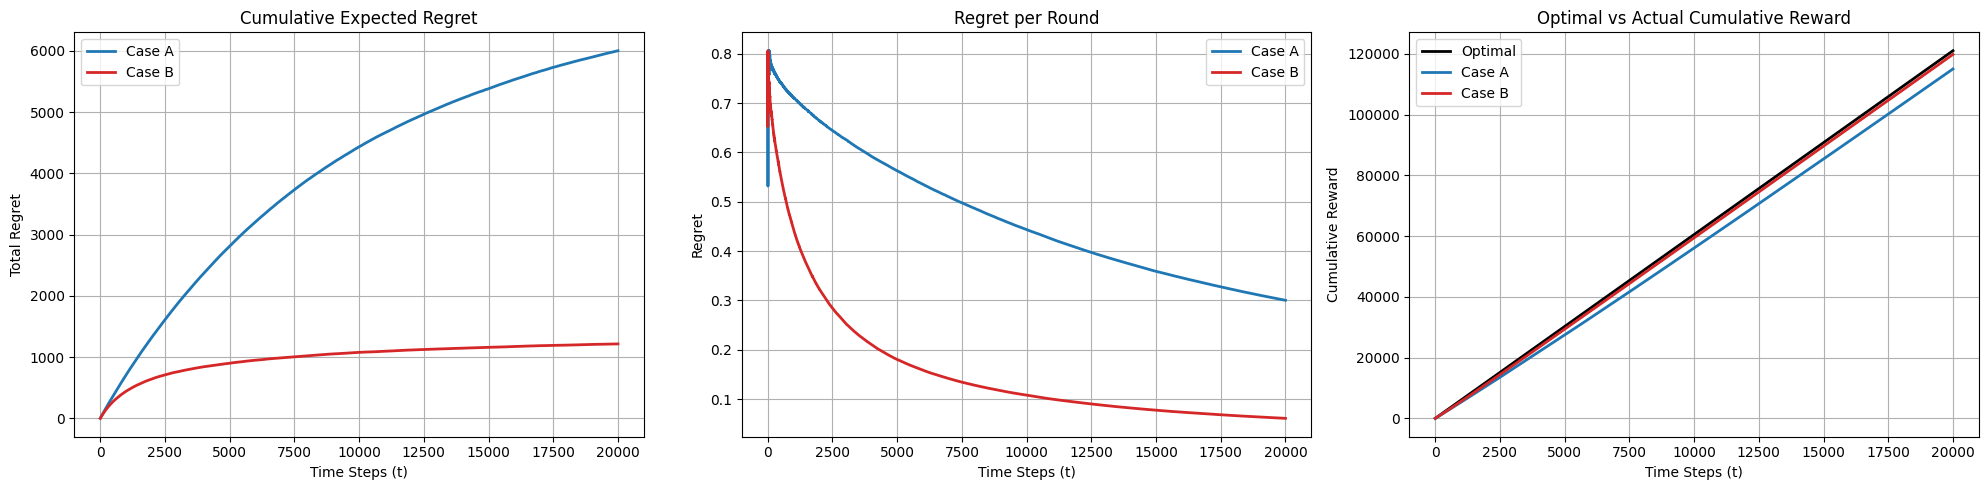

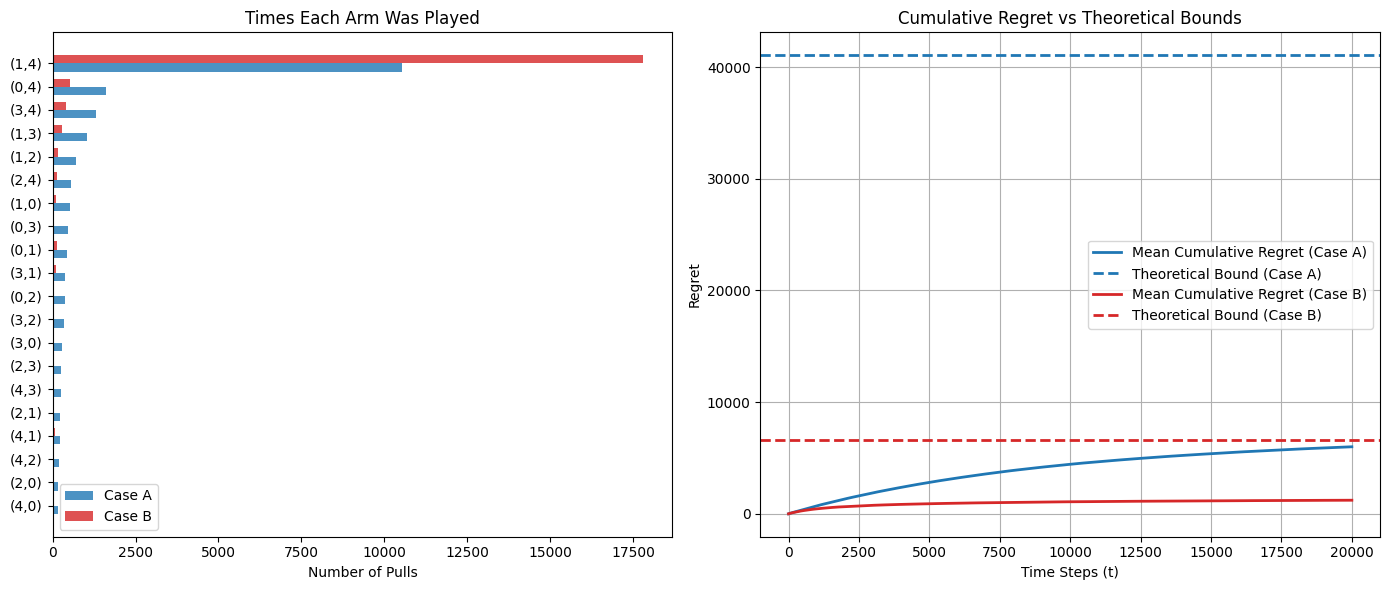

In [3]:
# Both cases (only plots)
import numpy as np
import matplotlib.pyplot as plt

K = 5
epsilon = 0.6
T = 20000
epochs = 10

# Create arms
arms = []
for j1 in range(K):
    for j2 in range(K):
        if j1 != j2:
            arms.append((j1, j2))

n_arms = len(arms)
time_axis = np.arange(1, T + 1)

# Create sample baseline SNR parameters
rng_base = np.random.default_rng(63)
snr_base = rng_base.uniform(0.8, 2.0, (2, 5))

# Expected reward computation
def F(s):
    return (1 + 10 * s) * (np.log(1 + 10 * s) - 1) / 10

def expected_reward(snr_base, epsilon):
    # Store user-channel expectations
    mu1 = np.zeros(K)
    mu2 = np.zeros(K)

    # Compute expectations once per channel
    for j in range(K):
        base1 = snr_base[0, j]
        base2 = snr_base[1, j]

        mu1[j] = (F(base1 + epsilon) - F(base1 - epsilon)) / (2 * epsilon)
        mu2[j] = (F(base2 + epsilon) - F(base2 - epsilon)) / (2 * epsilon)

    # Compute joint arm rewards
    mu_arms = []
    for j1 in range(K):
        for j2 in range(K):
            if j1 != j2:
                mu_arms.append(mu1[j1] + mu2[j2])

    return mu1, mu2, mu_arms

mu1, mu2, mu_arms = expected_reward(snr_base, epsilon)

# Best arm
best_idx = np.argmax(mu_arms)
best_mu = mu_arms[best_idx]
best_arm = arms[best_idx]

# Reward ranges
snr_min = 0.8 - epsilon
snr_max = 2.0 + epsilon

# Case A reward range
r_min_A = 2.0 * np.log(1.0 + 10.0 * snr_min)
r_max_A = 2.0 * np.log(1.0 + 10.0 * snr_max)
R_A = r_max_A - r_min_A

# Case B reward range (per user)
r_min_B = np.log(1.0 + 10.0 * snr_min)
r_max_B = np.log(1.0 + 10.0 * snr_max)
R_B = r_max_B - r_min_B


# =========================================================
# CASE A
# =========================================================
all_cumulative_regret_A = np.zeros((epochs, T))
all_regret_per_round_A = np.zeros((epochs, T))
all_cumulative_actual_reward_A = np.zeros((epochs, T))
all_arm_pulls_A = np.zeros((epochs, n_arms))

for epoch in range(epochs):
    delta = np.zeros(T)
    N = np.zeros(n_arms)
    sum_rewards = np.zeros(n_arms)
    actual_rewards = np.zeros(T)

    rng = np.random.default_rng(epoch)

    for t in range(1, T + 1):
        if t <= n_arms:
            chosen_arm = t - 1
        else:
            exploit_term = sum_rewards / N
            explore_term = R_A * np.sqrt((2 * np.log(T)) / N)
            ucb_score = exploit_term + explore_term
            chosen_arm = np.argmax(ucb_score)

        j1, j2 = arms[chosen_arm]
        base1 = snr_base[0, j1]
        base2 = snr_base[1, j2]

        snr_inst1 = rng.uniform(base1 - epsilon, base1 + epsilon)
        snr_inst2 = rng.uniform(base2 - epsilon, base2 + epsilon)

        rate1 = np.log(1 + 10 * snr_inst1)
        rate2 = np.log(1 + 10 * snr_inst2)

        total_rate = rate1 + rate2
        actual_rewards[t - 1] = total_rate

        N[chosen_arm] += 1
        sum_rewards[chosen_arm] += total_rate

        delta[t - 1] = best_mu - mu_arms[chosen_arm]

    cumulative_regret = np.cumsum(delta)
    regret_per_round = cumulative_regret / time_axis
    cumulative_actual_reward = np.cumsum(actual_rewards)

    all_cumulative_regret_A[epoch] = cumulative_regret
    all_regret_per_round_A[epoch] = regret_per_round
    all_cumulative_actual_reward_A[epoch] = cumulative_actual_reward
    all_arm_pulls_A[epoch] = N

mean_cumulative_regret_A = np.mean(all_cumulative_regret_A, axis=0)
mean_regret_per_round_A = np.mean(all_regret_per_round_A, axis=0)
mean_cumulative_actual_reward_A = np.mean(all_cumulative_actual_reward_A, axis=0)
mean_arm_pulls_A = np.mean(all_arm_pulls_A, axis=0)

# Suboptimality gaps excluding the optimal arm
delta_sub = np.array([best_mu - mu_arms[i] for i in range(n_arms) if i != best_idx])

# Theoretical bound at the final horizon T
bound_A = np.sum((8 * R_A**2 * np.log(T)) / delta_sub) + n_arms * R_A * T**(-2)

# =========================================================
# CASE B
# =========================================================
all_cumulative_regret_B = np.zeros((epochs, T))
all_regret_per_round_B = np.zeros((epochs, T))
all_cumulative_actual_reward_B = np.zeros((epochs, T))
all_arm_pulls_B = np.zeros((epochs, n_arms))

for epoch in range(epochs):
    N1 = np.zeros(K)
    sum_r1 = np.zeros(K)

    N2 = np.zeros(K)
    sum_r2 = np.zeros(K)

    N_joint = np.zeros(n_arms)
    delta = np.zeros(T)
    actual_rewards = np.zeros(T)

    rng = np.random.default_rng(epoch)

    for t in range(1, T + 1):
        if t <= K:
            j1 = t - 1
            j2 = t % K
        else:
            explore_term1 = R_B * np.sqrt((2 * np.log(T)) / N1)
            explore_term2 = R_B * np.sqrt((2 * np.log(T)) / N2)

            exploit_term1 = sum_r1 / N1
            exploit_term2 = sum_r2 / N2

            ucb1 = exploit_term1 + explore_term1
            ucb2 = exploit_term2 + explore_term2

            best_score = -np.inf
            for p1 in range(K):
                for p2 in range(K):
                    if p1 != p2:
                        current_score = ucb1[p1] + ucb2[p2]
                        if current_score > best_score:
                            best_score = current_score
                            j1, j2 = p1, p2

        chosen_arm = arms.index((j1, j2))

        snr_t1 = rng.uniform(snr_base[0, j1] - epsilon, snr_base[0, j1] + epsilon)
        snr_t2 = rng.uniform(snr_base[1, j2] - epsilon, snr_base[1, j2] + epsilon)

        r1 = np.log(1 + 10 * snr_t1)
        r2 = np.log(1 + 10 * snr_t2)

        total_rate = r1 + r2
        actual_rewards[t - 1] = total_rate

        N1[j1] += 1
        sum_r1[j1] += r1

        N2[j2] += 1
        sum_r2[j2] += r2
        N_joint[chosen_arm] += 1

        delta[t - 1] = best_mu - (mu1[j1] + mu2[j2])

    cumulative_regret = np.cumsum(delta)
    regret_per_round = cumulative_regret / time_axis
    cumulative_actual_reward = np.cumsum(actual_rewards)

    all_cumulative_regret_B[epoch] = cumulative_regret
    all_regret_per_round_B[epoch] = regret_per_round
    all_cumulative_actual_reward_B[epoch] = cumulative_actual_reward
    all_arm_pulls_B[epoch] = N_joint

mean_cumulative_regret_B = np.mean(all_cumulative_regret_B, axis=0)
mean_regret_per_round_B = np.mean(all_regret_per_round_B, axis=0)
mean_cumulative_actual_reward_B = np.mean(all_cumulative_actual_reward_B, axis=0)
mean_arm_pulls_B = np.mean(all_arm_pulls_B, axis=0)

# Best channels per user
j1_star, j2_star = best_arm

# Component gaps
Delta1 = []
Delta2 = []

for j in range(K):
    if j != j1_star:
        Delta1.append(mu1[j1_star] - mu1[j])

for j in range(K):
    if j != j2_star:
        Delta2.append(mu2[j2_star] - mu2[j])

Delta1 = np.array(Delta1)
Delta2 = np.array(Delta2)

# Compute bound terms
term1 = np.sum((8 * R_B**2 * np.log(T)) / Delta1)
term2 = np.sum((8 * R_B**2 * np.log(T)) / Delta2)
term3 = 2 * K * (2 * R_B) * T**(-2)
bound_B = term1 + term2 + term3

# =========================================================
# PLOTTING
# =========================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Cumulative Regret
axes[0].plot(time_axis, mean_cumulative_regret_A, color='tab:blue', linewidth=2, label='Case A')
axes[0].plot(time_axis, mean_cumulative_regret_B, color='tab:red', linewidth=2, label='Case B')
axes[0].set_title("Cumulative Expected Regret")
axes[0].set_xlabel("Time Steps (t)")
axes[0].set_ylabel("Total Regret")
axes[0].legend()
axes[0].grid(True)

# 2. Regret per Round
axes[1].plot(time_axis, mean_regret_per_round_A, color='tab:blue', linewidth=2, label='Case A')
axes[1].plot(time_axis, mean_regret_per_round_B, color='tab:red', linewidth=2, label='Case B')
axes[1].set_title("Regret per Round")
axes[1].set_xlabel("Time Steps (t)")
axes[1].set_ylabel("Regret")
axes[1].legend()
axes[1].grid(True)

# 3. Optimal vs Actual Cumulative Reward
optimal_cumulative_reward = best_mu * time_axis
axes[2].plot(time_axis, optimal_cumulative_reward, color='black', linewidth=2, label='Optimal')
axes[2].plot(time_axis, mean_cumulative_actual_reward_A, color='tab:blue', linewidth=2, label='Case A')
axes[2].plot(time_axis, mean_cumulative_actual_reward_B, color='tab:red', linewidth=2, label='Case B')
axes[2].set_title("Optimal vs Actual Cumulative Reward")
axes[2].set_xlabel("Time Steps (t)")
axes[2].set_ylabel("Cumulative Reward")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

print()
# 4. Number of pulls per arm (Sorted)
fig, axes = plt.subplots(1, 2, figsize=(14,6))
sorted_idx = np.argsort(mean_arm_pulls_A)
arm_labels = [f"({arms[i][0]},{arms[i][1]})" for i in sorted_idx]

y = np.arange(n_arms)
h = 0.35

axes[0].barh(y - h/2, mean_arm_pulls_A[sorted_idx], height=h,
             color='tab:blue', alpha=0.8, label='Case A')

axes[0].barh(y + h/2, mean_arm_pulls_B[sorted_idx], height=h,
             color='tab:red', alpha=0.8, label='Case B')

axes[0].set_yticks(y)
axes[0].set_yticklabels(arm_labels)
axes[0].set_title("Times Each Arm Was Played")
axes[0].set_xlabel("Number of Pulls")
axes[0].legend()

# 5. Cumulative Regret vs Theoretical Bounds
# Case A
axes[1].plot(time_axis, mean_cumulative_regret_A,
             color='tab:blue',
             linewidth=2,
             label="Mean Cumulative Regret (Case A)")

axes[1].axhline(bound_A,
                color='tab:blue',
                linestyle='--',
                linewidth=2,
                label="Theoretical Bound (Case A)")

# Case B
axes[1].plot(time_axis, mean_cumulative_regret_B,
             color='tab:red',
             linewidth=2,
             label="Mean Cumulative Regret (Case B)")

axes[1].axhline(bound_B,
                color='tab:red',
                linestyle='--',
                linewidth=2,
                label="Theoretical Bound (Case B)")

axes[1].set_title("Cumulative Regret vs Theoretical Bounds")
axes[1].set_xlabel("Time Steps (t)")
axes[1].set_ylabel("Regret")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()